<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/Machine-Learning/blob/main/244107020090_Fadhil_Taufiqurrachman_P11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Jobsheet 11 - Klasifikasi 2

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pembelajaran Mesin

Menyiapkan Data

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /Machine Learning/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Praktikum 1

Langkah 1 - Import Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from ipywidgets import interact, fixed

!pip install ipywidgets

Langkah 2 - Membuat Data Dummy

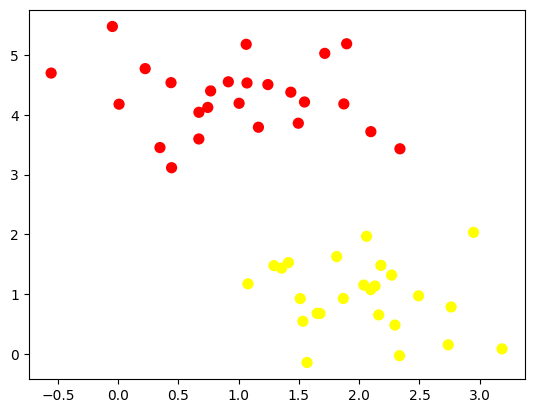

In [ ]:
# Membuat data dummy linier dengan 2 pusat (kelas)
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)

# Menampilkan hasil data dummy ke dalam scatter plot
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

Langkah 3 - Buat Ilustrasi Garis Pemisah

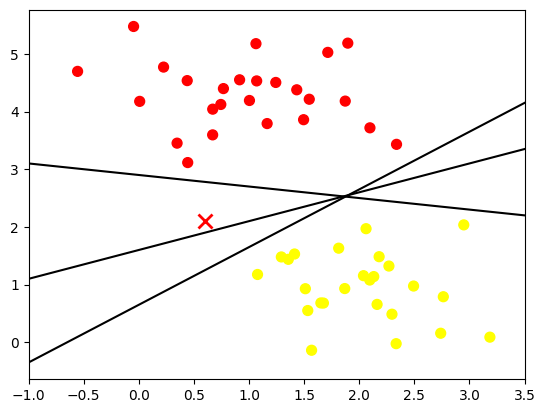

In [ ]:
# Membuat rentang nilai x untuk menggambar garis memanjang
xfit = np.linspace(-1, 3.5)

# Menampilkan data dummy awal (bulatan merah dan kuning)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menambahkan data baru berupa tanda silang merah pada koordinat x=0.6, y=2.1
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

# Membuat 3 variasi garis pemisah kandidat (m = gradien, b = intersep)
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

# Membatasi tampilan sumbu x agar rapi dan sesuai gambar referensi
plt.xlim(-1, 3.5)
plt.show()

Langkah 4 - Ilustrasi Margin

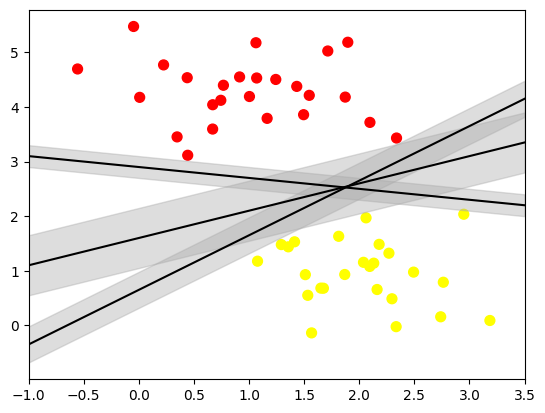

In [ ]:
# Membuat ilustrasi garis pemisah dan area margin
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Membuat 3 variasi garis pemisah beserta nilai marginnya
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.show()

Langkah 5 - Fitting Model

In [ ]:
# Melakukan pelatihan (fitting) model SVM dengan kernel linier
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

# Membuat fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none')

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

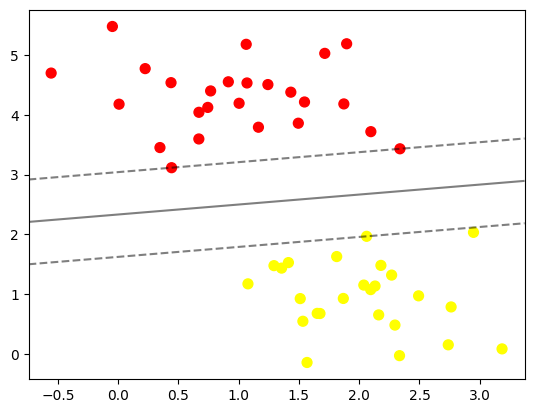

Koordinat Support Vectors:
 [[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]


In [ ]:
# Lakukan plotting dengan fungsi yang telah dibuat
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.show()

# Menampilkan titik data yang menjadi support vector
print("Koordinat Support Vectors:\n", model.support_vectors_)

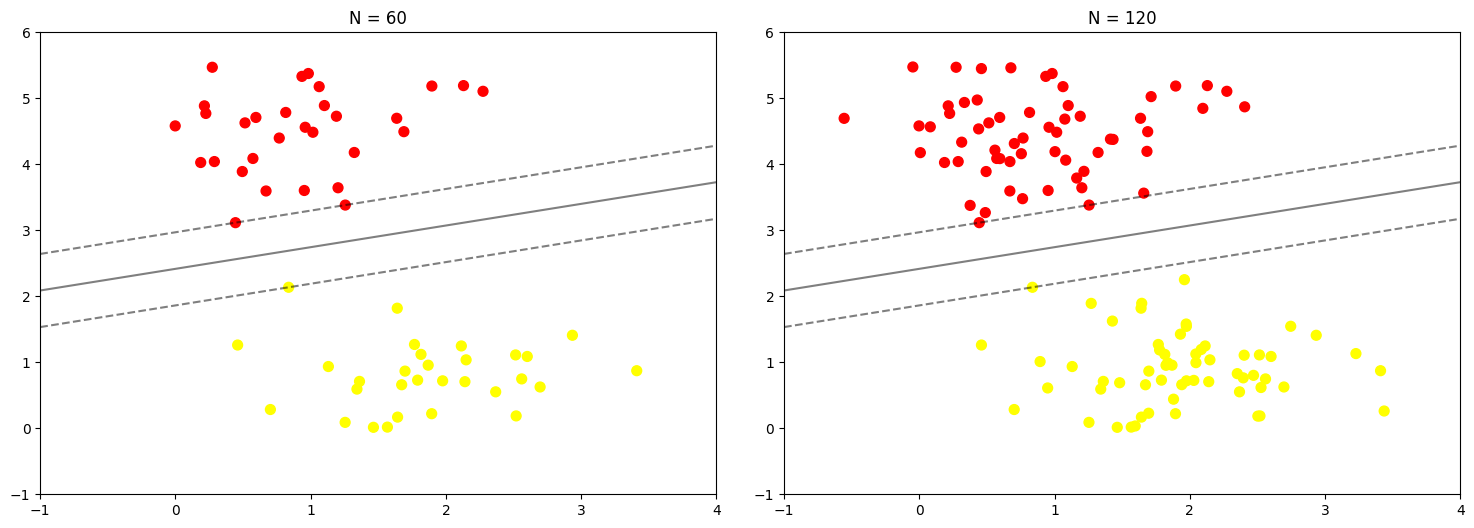

In [ ]:
# Fungsi untuk melihat pengaruh jumlah data terhadap fitting model
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

# Membandingkan model jika dilatih dengan 60 sampel vs 120 sampel awal
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

In [ ]:
# Jumlah data dapat dipilih di antara 10 atau 200 buah data
interact(plot_svm, N=[10, 50, 100, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 50, 100, 200), value=10), Output()), _dom_classes…

<function __main__.plot_svm(N=10, ax=None)>

Praktikum pertama ini menyimulasikan secara jelas prinsip fundamental dari Support Vector Machine (SVM) sebagai algoritma klasifikasi. Melalui simulasi dengan data dummy, dapat dianalisis bahwa keberhasilan dan letak batas keputusan (garis hyperplane) dari model SVM ditentukan secara eksklusif oleh support vectors, yaitu beberapa titik data spesifik yang terletak paling dekat dengan margin pemisah. Hal ini dibuktikan secara empiris pada perbandingan dataset berjumlah 60 versus 120 titik data, di mana penambahan jumlah observasi yang posisinya berada jauh di luar area batas klasifikasi sama sekali tidak mengubah letak hyperplane maupun memodifikasi fitting model yang ada. Sifat ini mengonfirmasi stabilitas dan efisiensi algoritma SVM karena loss function-nya hanya bergantung pada sampel-sampel kritis (titik support vector) sehingga kebal terhadap penambahan data mayoritas yang redundan.

### Praktikum 2

Import Library

In [ ]:
# Import fungsi untuk membuat data dummy berbentuk lingkaran (non-linier)
from sklearn.datasets import make_circles
# Import library untuk plotting 3D
from mpl_toolkits import mplot3d

Langkah 1 - Buat Data Dummy Non-Linier

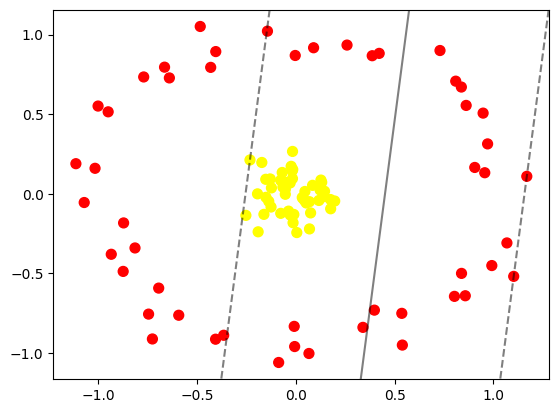

In [ ]:
# Membuat 100 sampel data dummy non-linier dengan noise
X, y = make_circles(100, factor=.1, noise=.1)

# Mencoba memisahkan data dengan SVM linear (yang akan gagal)
clf = SVC(kernel='linear').fit(X, y)

# Visualisasi data dan hasil batas keputusan dari SVM linear
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)
plt.show()

In [ ]:
# Menghitung proyeksi berbasis radial
r = np.exp(-(X ** 2).sum(1))

# Fungsi untuk memvisualisasikan data dalam ruang 3D
def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

# Membuat plot interaktif (memerlukan instalasi ipywidgets)
interact(plot_3D, elev=[-90, -45, 0, 45, 90], azip=(-180, 180),
         X=fixed(X), y=fixed(y))
plt.show()

interactive(children=(Dropdown(description='elev', options=(-90, -45, 0, 45, 90), value=-90), IntSlider(value=…

Langkah 2 - Fitting Model

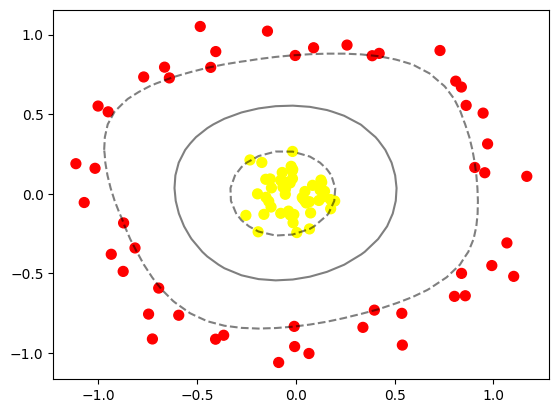

In [ ]:
# Melatih model SVM menggunakan kernel Radial Basis Function (RBF)
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

# Visualisasi data, batas keputusan melingkar, dan support vectors
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')
plt.show()

Praktikum kedua ini secara spesifik mendemonstrasikan keunggulan algoritma Support Vector Machine (SVM) dalam menyelesaikan masalah klasifikasi pada data yang distribusinya bersifat non-linier. Pada observasi awal (Langkah 1c), model SVM yang menggunakan kernel dasar linier terbukti gagal memberikan batasan yang akurat pada sebaran data berbentuk cincin melingkar. Solusi untuk kendala ini dibuktikan melalui penerapan konsep proyeksi ruang dengan mentransformasikan data 2D ke dalam dimensi 3D menggunakan fungsi matematis radial. Pemanfaatan kernel trick jenis Radial Basis Function (RBF) ini memungkinkan algoritma mengkalkulasi dan membentuk decision boundary berupa kurva melingkar secara efisien tanpa beban komputasi besar, sehingga titik data kuning dan merah dapat terklasifikasi dengan sempurna.

### Praktikum 3

Langkah 1 - Buat Data Dummy

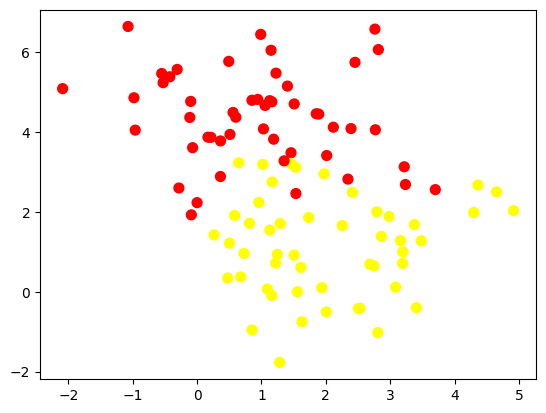

In [ ]:
# Membuat 100 sampel data dummy dengan standar deviasi klaster yang lebih besar (1.2)
# Hal ini akan menyebabkan sebaran data kelas merah dan kuning menjadi saling tumpang tindih
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)

# Menampilkan hasil sebaran data overlapping ke dalam scatter plot
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

Langkah 2 - Analisis Dampak Tunning

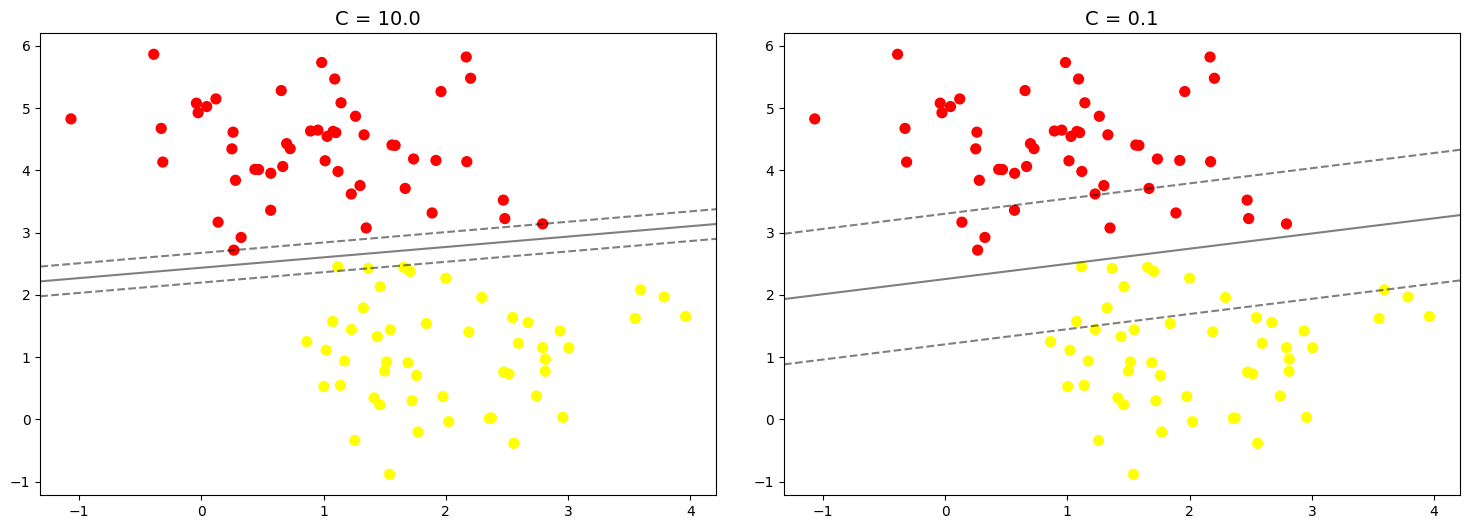

In [ ]:
# Membuat ulang data dummy dengan tingkat overlap yang sedikit dikurangi (std=0.8) untuk visualisasi perbandingan
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

# Menyiapkan figur matplotlib untuk membandingkan 2 plot secara bersebelahan
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

# Melakukan iterasi untuk membandingkan model dengan nilai C = 10.0 dan C = 0.1
for axi, C in zip(ax, [10.0, 0.1]):
    # Melatih model SVM linier dengan menyertakan parameter C
    model = SVC(kernel='linear', C=C).fit(X, y)

    # Plotting sebaran data
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

    # Memanggil fungsi plot batas keputusan dan margin
    plot_svc_decision_function(model, axi)

    # Menandai titik-titik yang menjadi support vectors
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none')

    # Memberikan judul berdasarkan nilai C yang digunakan
    axi.set_title('C = {0:.1f}'.format(C), size=14)

plt.show()

Praktikum ketiga ini menjelaskan teknik penanganan masalah klasifikasi pada kondisi dunia nyata di mana sebaran kelas data sering kali saling tumpang tindih (overlapping) dan tidak dapat dipisahkan secara absolut. Sebagai solusinya, SVM menerapkan metode hyperparameter tuning melalui manipulasi nilai C yang berfungsi untuk mengatur tingkat "penghalusan margin" ( soft margin). Berdasarkan hasil visualisasi komparatif, penggunaan nilai C = 10.0 (lebih besar) menghasilkan margin yang tipis dan ketat karena algoritma memberikan penalti yang tinggi terhadap data yang melanggar batas, sedangkan nilai C = 0.1 (lebih kecil) menciptakan penebalan area margin yang mengizinkan beberapa titik data masuk ke dalam area tersebut demi mendapatkan garis fitting keseluruhan yang lebih baik dan tergeneralisasi. Karena sensitivitas ini, penentuan nilai C yang paling optimal tidak bisa ditebak, melainkan harus disesuaikan secara empiris untuk setiap karakteristik dataset melalui prosedur seperti cross-validation.

### Praktikum 4

Langkah 1 - Unduh Dataset

In [ ]:
# Import library khusus untuk mengunduh dataset wajah LFW
from sklearn.datasets import fetch_lfw_people

# Mengunduh dataset
# Syarat: hanya mengambil tokoh yang memiliki minimal 60 gambar wajah
faces = fetch_lfw_people(min_faces_per_person=60, data_home=BASE_PATH)

print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


Langkah 2 - Inspeksi Citra Wajah

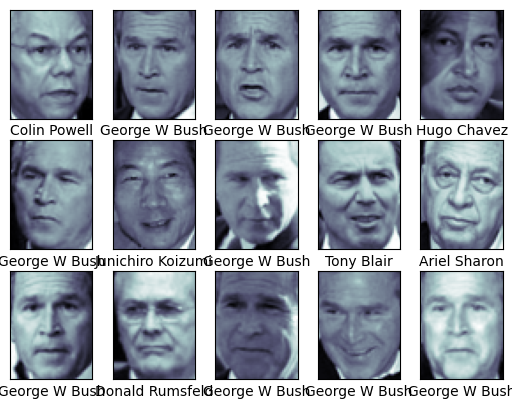

In [ ]:
# Menampilkan contoh wajah yang digunakan dari dataset
fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.show()

Langkah 3 - Pra Pengolahan Data

In [ ]:
# Import modul untuk PCA dan Pipeline
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

# Menggunakan PCA untuk ekstraksi fitur utama (mereduksi dimensi)
pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)

# Menggunakan SVM dengan kernel RBF untuk menangani data non-linier yang kompleks
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam 1 eksekusi
model = make_pipeline(pca, svc)

Langkah 4 - Split Data

In [ ]:
# Pemisahan data training dan data testing
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

Langkah 5 - Pembuatan Model + Tunning

In [ ]:
# Import modul untuk hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Menentukan kombinasi parameter C dan gamma yang akan diuji
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}

# Menjalankan GridSearch untuk mencari performa model terbaik
grid = GridSearchCV(model, param_grid)

# Mengukur waktu eksekusi proses training (gunakan %time)
%time grid.fit(Xtrain, ytrain)

print(grid.best_params_)
print(grid.best_score_)

# Gunakan model dengan parameter terbaik tersebut untuk proses prediksi
model = grid.best_estimator_
yfit = model.predict(Xtest)

CPU times: user 2min 16s, sys: 21.7 ms, total: 2min 16s
Wall time: 1min 43s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


Langkah 6 - Cek Hasil Prediksi

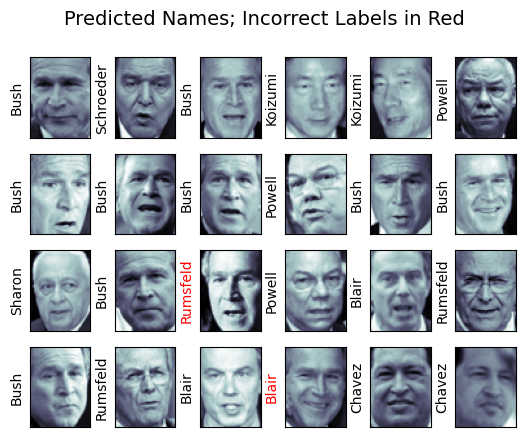

In [ ]:
# Visualisasi hasil prediksi label pada data testing
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])

    # Memberi warna hitam jika prediksi benar, merah jika prediksi salah
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')

fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)
plt.show()

Langkah 7 - Cek Performansi

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



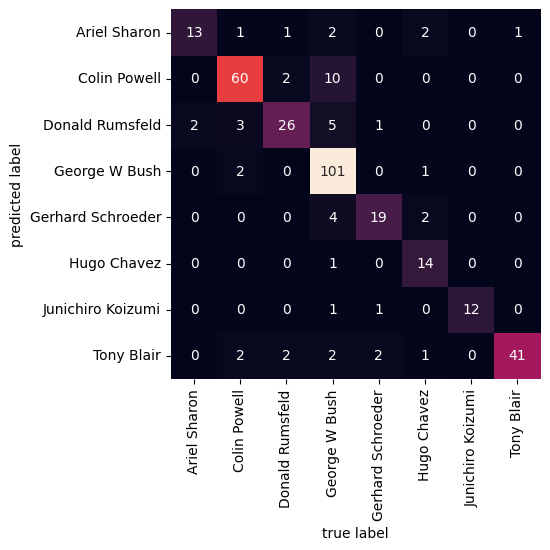

In [ ]:
# Import metrik evaluasi model
from sklearn.metrics import classification_report, confusion_matrix

# Menampilkan report performa keseluruhan (Precision, Recall, F1-Score)
print(classification_report(ytest, yfit, target_names=faces.target_names))

# Membentuk visualisasi confusion matrix
mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)

plt.xlabel('true label')
plt.ylabel('predicted label')
plt.show()

Praktikum ini mendemonstrasikan implementasi algoritma Support Vector Machine (SVM) pada kasus dunia nyata berskala kompleks, yaitu klasifikasi citra wajah (image recognition) publik figur. Berbeda dengan data dummy sebelumnya, gambar wajah memiliki dimensi resolusi yang sangat tinggi, sehingga diterapkan Principal Component Analysis (PCA) sebagai tahap pra-pengolahan guna mereduksi fitur dan hanya mempertahankan 150 komponen utama (principal components) terpenting untuk dipelajari oleh model. Optimalisasi algoritma kemudian dilakukan melalui hyperparameter tuning menggunakan GridSearchCV secara iteratif, yang sukses menemukan kombinasi terbaik untuk batas (soft margin) C=5 dan radius sebaran kernel RBF Gamma=0.001 dengan akurasi training yang baik. Berdasarkan metrik evaluasi akhir dari classification report dan persebaran pada confusion matrix, model ini terbukti handal dalam mengenali pola rumit dengan tingkat ketepatan (precision dan recall) yang tinggi secara keseluruhan, di mana model mampu mengklasifikasikan tokoh dominan seperti George W. Bush dengan 101 prediksi benar tanpa banyak error pada kelas lainnya.

### Praktikum 5

Langkah 1 - Import Library dan Set Direktori

In [ ]:
from pathlib import Path
import matplotlib.image as mpimg
import cv2
import random
import pandas as pd

train_dir = BASE_PATH + "images/training/"
test_dir = BASE_PATH + "images/test/"

Langkah 2 - Load Data dan Visualisasikan

In [ ]:
def load_dataset_safe(img_dir):
    p = Path(img_dir)
    img_list = []

    # Memaksa pencarian hanya pada subfolder yang valid
    for label in ['day', 'night']:
        dir_path = p / label
        if dir_path.exists():
            jpg_files = list(dir_path.glob('*.jpg'))
            print(f"✓ Berhasil memuat {len(jpg_files)} gambar dari folder '{label}'")
            for file in jpg_files:
                img = mpimg.imread(file)
                if img is not None:
                    img_list.append((img, label))
        else:
            print(f"⚠ ERROR: Folder {dir_path} TIDAK DITEMUKAN!")

    return img_list

Image 111
(469, 640, 3)
Shape	: (458, 800, 3)
Label	: day (1)


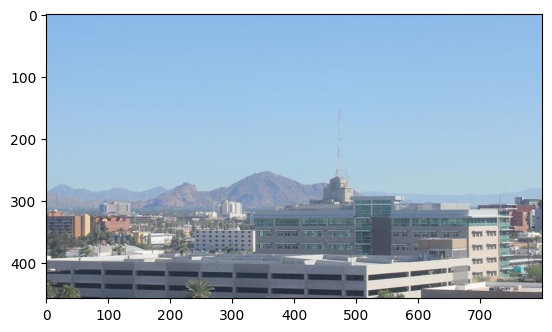

In [ ]:
# Cek ukuran gambar secara acak
pick_random = np.random.randint(0, len(train_img))
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

# Membuat fungsi untuk visualisasi gambar dan label secara rapi
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night' # Opsional jika label sudah string

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')
    plt.show()

# Melakukan visualisasi gambar acak dari data training
random_img_viz(train_img)

Langkah 3 - Pra Pengolahan Data

In [ ]:
# Fungsi untuk menyamakan ukuran seluruh gambar menjadi 1100x600 piksel
def standarized_input(image):
    std_img = cv2.resize(image, (1100, 600))
    return std_img

# Fungsi untuk mengubah label teks menjadi angka biner (1 untuk 'day', 0 untuk 'night')
def label_encoder(label):
    num_val = 0
    if(label == 'day'):
        num_val = 1
    return num_val

# Fungsi utama untuk melakukan pra-pengolahan secara menyeluruh pada list gambar
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        std_img = standarized_input(image)
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

# Eksekusi pra-pengolahan pada data training
train_std_img_list = preprocess(train_img)

# Verifikasi ukuran gambar setelah pra-pengolahan
pick_random = np.random.randint(0, len(train_std_img_list))
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 86
(600, 1100, 3)


Langkah 4 - Ekstraksi Fitur

Image 143
Avg Brightness: 104.0629


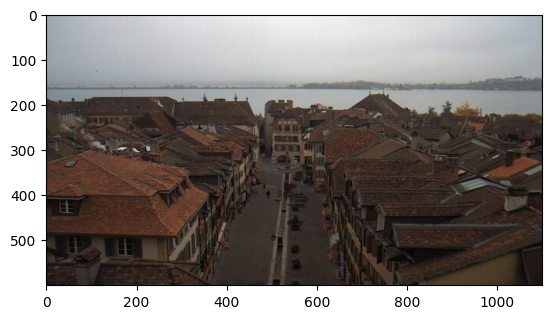

In [ ]:
# Fungsi ekstraksi fitur: Menghitung rata-rata nilai "Value" (kecerahan) dari ruang warna HSV
def avg_brightness(image):
    # Mengubah format warna RGB ke HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Menjumlahkan seluruh piksel pada channel V (indeks 2)
    sum_brightness = np.sum(img_hsv[:,:,2])

    # Membagi dengan total luas area gambar
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

# Uji coba fungsi ekstraksi fitur pada gambar acak yang telah terstandarisasi
rand_img = np.random.randint(0, len(train_std_img_list))
feature_img = train_std_img_list[rand_img][0]
avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brightness: {avg_img:.4f}')
plt.imshow(feature_img)
plt.show()

Langkah 5 - Klasifikasi dengan Metode Threshold

Image 201
Actual label: 0
Predicted label: 1


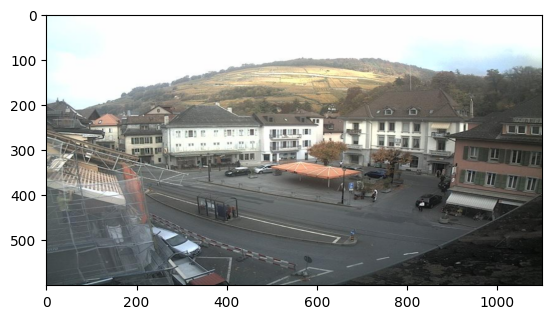

In [ ]:
# Fungsi prediksi klasifikasi sederhana berdasarkan nilai ambang batas kecerahan
def predict_label(img, threshold):
    avg = avg_brightness(img)
    pred = 0 # Default ke 'night' (0)

    if avg > threshold:
        pred = 1 # Ubah ke 'day' (1) jika lebih terang dari threshold

    return pred

# Test the classifier on train data (Pengecekan acak)
rand_img = np.random.randint(0, len(train_std_img_list))

# Memprediksi gambar acak menggunakan fungsi predict_label dengan threshold 120
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate (Menampilkan hasil)
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')

# Menampilkan gambar yang diprediksi
plt.imshow(train_std_img_list[rand_img][0])
plt.show()

Langkah 6 - Evaluasi Manual

In [ ]:
# Fungsi untuk menghitung akurasi prediksi manual secara keseluruhan
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        img = file[0]
        label = file[1]

        pred_label = predict_label(img, threshold)

        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

# Evaluasi tingkat akurasi pada data training jika threshold disetel di angka 120
print("Evaluasi Manual (Threshold=120) - Data Training:")
evaluate(train_std_img_list, threshold=120)

# Melakukan persiapan dan evaluasi yang sama pada data testing
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)

print("Evaluasi Manual (Threshold=120) - Data Testing:")
evaluate(test_std_img_list, threshold=120)

Evaluasi Manual (Threshold=120) - Data Training:
Accuracy: 0.6583
Evaluasi Manual (Threshold=120) - Data Testing:
Accuracy: 0.8688


### Klasifikasi Dengan SVM

Langkah 4 Alternatif - Membuat Feature Vectors

In [ ]:
# Fungsi ekstraksi fitur massal dan menyimpannya secara rapi dalam format DataFrame (Tabel)
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    # Menggabungkan data kolom
    data = np.column_stack((avg_list, labels))
    # Membuat DataFrame dari Pandas
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

# Ekstrak seluruh fitur training ke dalam tabel dan periksa formatnya
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape Data Training: {train_avg_img.shape}')
display(train_avg_img.head())

# Lakukan hal yang sama untuk data testing
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape Data Testing: {test_avg_img.shape}')
display(test_avg_img.head())

Shape Data Training: (240, 2)


,AVG_BRIGHT,LABELS
0,48.313274,0.0
1,29.425348,0.0
2,25.862577,0.0
3,25.678615,0.0
4,48.420536,0.0


Shape Data Testing: (160, 2)


,AVG_BRIGHT,LABELS
0,8.217803,0.0
1,98.235594,0.0
2,13.765597,0.0
3,13.655582,0.0
4,32.609429,0.0


Langkah 5 - Buat Model SVM

In [ ]:
print("\n--- MELATIH MODEL SVM ---")
X_train = df_train[['AVG_BRIGHT']].values
y_train = df_train['LABELS'].values.astype(int)

X_test = df_test[['AVG_BRIGHT']].values
y_test = df_test['LABELS'].values.astype(int)

model = SVC(kernel='rbf')
model.fit(X_train, y_train)


--- MELATIH MODEL SVM ---


SVC()

Langkah 6 - Evaluasi

In [ ]:
# Melakukan evaluasi performansi model SVM
from sklearn.metrics import accuracy_score

y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train\t: {acc_train}')
print(f'Accuracy on test\t: {acc_test}')

Accuracy on train	: 0.8583333333333333
Accuracy on test	: 0.9


Mendemonstrasikan keseluruhan alur kerja (pipeline) computer vision, mulai dari inspeksi, standarisasi gambar, ekstraksi fitur tingkat kecerahan berbasis ruang warna HSV, hingga proses klasifikasi citra bertema siang dan malam. Percobaan ini sangat menarik karena membandingkan langsung dua pendekatan klasifikasi. Pendekatan pertama menggunakan metode Threshold statis (aturan If-Else) yang mematok batas kecerahan manual, yang meskipun sederhana, tingkat akurasinya bergantung penuh pada tebakan pengguna dan rawan error. Pendekatan kedua menggunakan algoritma Support Vector Machine (SVM) modern yang mengambil data kompilasi numerik (feature vectors) dan secara otomatis mengkalkulasi batas pemisahan kelas (hyperplane) yang paling optimal menggunakan konfigurasi kernel RBF. Terbukti, pendekatan algoritma otomatis mesin SVM mencatatkan performa generalisasi yang jauh lebih superior, menghasilkan evaluasi akhir dengan tingkat akurasi prediksi data testing menyentuh angka tinggi sebesar 90%.